# HCAHPS Hospital Survey - Data Cleaning & Feature Engineering
**Project:** Predicting Hospital Patient Satisfaction (Predictive Analytics, Fall 2026)

**Source:** CMS Provider Data Catalog, *Patient survey (HCAHPS) – Hospital*, dataset
(https://data.cms.gov/provider-data/dataset/dgck-syfz), reporting period 10/01/2024 – 09/30/2025.

**Goal:** turn the raw long-format file (one row per hospital × survey measure) into a
**one-row-per-hospital** table for regression, classification, PCA and clustering.

| Part | What happens |
|---|---|
| **0. Setup** | Libraries, file paths, every cleaning rule in one config cell |
| **1. Raw data profile** | What the file contains *before* anything is changed |
| **2. Cleaning** (C1–C9) | Fix types, validate, reshape, select variables, exclude unreliable hospitals |
| **3. Feature engineering** (F1–F5) | New variables built *only* from the cleaned table, each documented |
| **4. Diagnostics** | Correlation and multicollinearity — informs modeling, changes nothing |
| **5. Export** | Model-ready file, data dictionary, cleaning log |

Each step has three parts: **What** we do, **Why**, and a **Check** printed by the code, so the output doubles as evidence for the report.

### What changed from v1 (summary of the review)
| # | v1 issue | v2 fix |
|---|---|---|
| 1 | CMS footnote columns for answer % and star rating were dropped; footnote **11 = "discrepancies in the data collection process"** hospitals stayed in the sample | All footnote columns kept and combined per hospital; footnote-11 hospitals excluded (config switch), footnote 3 flagged |
| 2 | Only survey counts were checked for consistency; response rate and footnotes were taken with `max` / `first` unchecked | All hospital-level fields checked |
| 3 | No validity checks on values (range 0–100, answer categories summing to 100, one reporting period) | Explicit checks in C4 |
| 4 | `errors="coerce"` could silently turn unexpected text into NaN | Unexpected strings counted and reported |
| 5 | Same-outcome columns (overall rating, summary star rating, recommend linear score) sat beside predictors with neutral names | Renamed with `alt_outcome_` prefix so they can't slip into X |
| 6 | Item-level questions are near-exact averages of the composites (r ≈ 0.99) but were z-scored *together* with them for PCA | Standardized file contains composites only; items documented as substitutes |
| 7 | `nurse_minus_doctor` = exact linear combination of two predictors (perfect collinearity if used with both) | Kept, renamed, explicit usage rule |
| 8 | `large_sample` (≥300 surveys) described as a "hospital size" proxy — 300 is CMS's *survey target*, not a size measure | Renamed `meets_300_survey_target`; added `log_completed_surveys` (raw counts are skew ≈ 4.4) |
| 9 | `region.fillna("Territory")` would silently label any typo/unknown state as a territory | Explicit mapping, assertion that nothing is unmapped |
| 10 | Median cutoff for the binary target described as "balanced" (actually 52/48 because of 124 ties at the median); computed on the full sample | Exact split reported; rule documented; recompute on training data for modeling |
| 11 | Data dictionary left descriptions blank for every derived / context column | Every column described; export fails if one is missing |
| 12 | Survey counts, response rate and footnote stored as floats; Facility ID loses leading zeros if read without `dtype=str` | Integer types; read instruction in the dictionary |
| 13 | Exclusions reduced 4,790 → 3,183 hospitals (66%) without describing who was dropped | Exclusion funnel + included-vs-excluded comparison |

## Part 0: Setup and configuration
Every rule that changes which rows or columns survive is set here, so a reader can see all decisions in one place.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)

# ----------------------------- CONFIG -----------------------------
RAW_FILE    = Path("HCAHPS-Hospital.csv")     # full CMS download (~100 MB)
OUTPUT_DIR  = Path("hcahps_output")

MIN_COMPLETED_SURVEYS = 100     # CMS footnote 6: scores from < 100 surveys are less reliable
EXCLUDE_FOOTNOTE_CODES = {11}   # 11 = discrepancies in the data collection process
FLAG_FOOTNOTE_CODES    = {3: "flag_shorter_period"}   # 3 = results cover a shorter period than required
SURVEY_TARGET = 300             # CMS target number of completed surveys per hospital per year
TARGET_CUTOFF_RULE = "median"   # "median" or "top_quartile" for the binary target
ANSWER_SUM_TOLERANCE = 3        # answer categories may sum to 97-103 because CMS rounds each to an integer
# ------------------------------------------------------------------
OUTPUT_DIR.mkdir(exist_ok=True)
cleaning_log = []               # (step, hospitals_remaining, note) -> exported as cleaning_log.csv

## Part 1 : Raw data profile (what the file contains before cleaning)
**What:** load every column as text and describe it.
**Why:** reading as text keeps Facility IDs like `010001` intact and lets us see placeholder strings
(`Not Available`, `Not Applicable`) before they are converted.

**Structure of the raw file (22 columns, long format):**

| Raw column | Content | Kept? |
|---|---|---|
| Facility ID | 6-character CMS Certification Number (leading zeros matter) | ✔ key |
| Facility Name, City/Town, State | Hospital identity / location | ✔ |
| Address, ZIP Code, County/Parish, Telephone Number | Contact details | ✘ not needed for modeling |
| HCAHPS Measure ID | Code for the survey measure, e.g. `H_COMP_1_A_P` | ✔ |
| HCAHPS Question, HCAHPS Answer Description | Text of the question / answer category | ✔ (for the inventory) |
| Patient Survey Star Rating (+ Footnote) | 1–5 stars; filled only on `*_STAR_RATING` rows | ✔ |
| HCAHPS Answer Percent (+ Footnote) | % of patients giving that answer; filled only on percent rows | ✔ |
| HCAHPS Linear Mean Value | 0–100 linear score; filled only on `*_LINEAR_SCORE` rows | ✔ |
| Number of Completed Surveys (+ Footnote) | Same on every row of a hospital | ✔ |
| Survey Response Rate Percent (+ Footnote) | Same on every row of a hospital | ✔ |
| Start Date, End Date | Reporting period | checked, then dropped |

In [2]:
raw_long = pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False)

n_raw_rows, n_raw_cols = raw_long.shape
n_raw_hospitals = raw_long["Facility ID"].nunique()
n_raw_measures  = raw_long["HCAHPS Measure ID"].nunique()
print(f"Raw file: {n_raw_rows:,} rows x {n_raw_cols} columns")
print(f"Hospitals: {n_raw_hospitals:,} | distinct measures: {n_raw_measures} | "
      f"rows per hospital: {n_raw_rows / n_raw_hospitals:.1f}")

reporting_periods = raw_long[["Start Date", "End Date"]].drop_duplicates()
print("Reporting period(s):", reporting_periods.to_dict("records"))
assert len(reporting_periods) == 1, "More than one reporting period: filter to one before continuing."

cleaning_log.append(("Raw file", n_raw_hospitals, f"{n_raw_rows:,} rows, {n_raw_measures} measures"))
raw_long.head(3)

Raw file: 325,720 rows x 22 columns
Hospitals: 4,790 | distinct measures: 68 | rows per hospital: 68.0
Reporting period(s): [{'Start Date': '10/01/2024', 'End Date': '09/30/2025'}]


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description,Patient Survey Star Rating,Patient Survey Star Rating Footnote,HCAHPS Answer Percent,HCAHPS Answer Percent Footnote,HCAHPS Linear Mean Value,Number of Completed Surveys,Number of Completed Surveys Footnote,Survey Response Rate Percent,Survey Response Rate Percent Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_A_P,"Patients who reported that their nurses ""Always"" communicated well","Nurses ""always"" communicated well",Not Applicable,,76,,Not Applicable,1392,,17,,10/01/2024,09/30/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_SN_P,"Patients who reported that their nurses ""Sometimes"" or ""Never"" com...","Nurses ""sometimes"" or ""never"" communicated well",Not Applicable,,6,,Not Applicable,1392,,17,,10/01/2024,09/30/2025
2,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_U_P,"Patients who reported that their nurses ""Usually"" communicated well","Nurses ""usually"" communicated well",Not Applicable,,18,,Not Applicable,1392,,17,,10/01/2024,09/30/2025


### 1b. Measure inventory
Each Measure ID ends with a suffix that says what kind of value the row holds and which column it sits in.

| Suffix | Meaning | Value column |
|---|---|---|
| `_A_P`, `_Y_P`, `_9_10`, `_DY` (and `_SA` if present) | **Top-box %** — the best answer ("Always", "Yes", rating 9–10, "Definitely yes") | Answer Percent |
| `_U_P`, `_SN_P`, `_N_P`, `_7_8`, `_0_6`, `_PY`, `_DN` | Other answer categories | Answer Percent |
| `_LINEAR_SCORE` | 0–100 linear mean score | Linear Mean Value |
| `_STAR_RATING` | 1–5 stars | Patient Survey Star Rating |

In [3]:
def classify_measure(measure_id: str) -> str:
    # Return the kind of value a measure row holds, based on its ID suffix.
    if measure_id.endswith("_LINEAR_SCORE"):
        return "linear_score"
    if measure_id.endswith("_STAR_RATING"):
        return "star_rating"
    if re.search(r"(_A_P|_Y_P|_SA|_9_10|_DY)$", measure_id):
        return "top_box_pct"
    return "other_pct"

measure_inventory = (raw_long.groupby("HCAHPS Measure ID")
                     .agg(answer_description=("HCAHPS Answer Description", "first"),
                          n_hospitals=("Facility ID", "nunique"))
                     .reset_index().rename(columns={"HCAHPS Measure ID": "measure_id"}))
measure_inventory["value_kind"] = measure_inventory["measure_id"].map(classify_measure)
measure_inventory["measure_group"] = measure_inventory["measure_id"].str.replace(
    r"_(A_P|U_P|SN_P|Y_P|N_P|SA|A|D_SD|9_10|7_8|0_6|DY|PY|DN|LINEAR_SCORE|STAR_RATING)$", "", regex=True)

print(measure_inventory["value_kind"].value_counts().to_string())
measure_inventory.to_csv(OUTPUT_DIR / "measure_inventory.csv", index=False)
measure_inventory

value_kind
other_pct       33
top_box_pct     18
star_rating      9
linear_score     8


,measure_id,answer_description,n_hospitals,value_kind,measure_group
0,H_CLEAN_HSP_A_P,"Room was ""always"" clean",4790,top_box_pct,H_CLEAN_HSP
1,H_CLEAN_HSP_SN_P,"Room was ""sometimes"" or ""never"" clean",4790,other_pct,H_CLEAN_HSP
2,H_CLEAN_HSP_U_P,"Room was ""usually"" clean",4790,other_pct,H_CLEAN_HSP
3,H_CLEAN_LINEAR_SCORE,Cleanliness - linear mean score,4790,linear_score,H_CLEAN
4,H_CLEAN_STAR_RATING,Cleanliness - star rating,4790,star_rating,H_CLEAN
...,...,...,...,...,...
63,H_SIDE_EFFECTS_SN_P,"Staff ""sometimes"" or ""never"" explained possible side effects",4790,other_pct,H_SIDE_EFFECTS
64,H_SIDE_EFFECTS_U_P,"Staff ""usually"" explained possible side effects",4790,other_pct,H_SIDE_EFFECTS
65,H_STAR_RATING,Summary star rating,4790,star_rating,H
66,H_SYMPTOMS_N_P,"No, staff ""did not"" give patients information about possible symptoms",4790,other_pct,H_SYMPTOMS


### 1c. Placeholder strings in the value columns
* **Not Applicable** — structural: the column does not apply to that row's measure (a percent row has no star rating). Safe to ignore.
* **Not Available** — real missingness: the hospital did not report, or had too few surveys. Counted again after reshaping (C8).

In [4]:
RAW_VALUE_COLUMNS = ["Patient Survey Star Rating", "HCAHPS Answer Percent", "HCAHPS Linear Mean Value",
                     "Number of Completed Surveys", "Survey Response Rate Percent"]
placeholder_profile = pd.DataFrame({
    col: {"Not Available": raw_long[col].str.strip().eq("Not Available").mean(),
          "Not Applicable": raw_long[col].str.strip().eq("Not Applicable").mean(),
          "blank": raw_long[col].str.strip().eq("").mean()}
    for col in RAW_VALUE_COLUMNS}).T.mul(100).round(1)
print("Share of rows (%) holding each placeholder:")
placeholder_profile

Share of rows (%) holding each placeholder:


,Not Available,Not Applicable,blank
Patient Survey Star Rating,4.4,86.8,0.0
HCAHPS Answer Percent,16.1,25.0,0.0
HCAHPS Linear Mean Value,3.9,88.2,0.0
Number of Completed Surveys,17.6,0.0,0.0
Survey Response Rate Percent,17.6,0.0,0.0


### 1d. CMS footnote codes present
Footnotes are CMS's own data-quality warnings. Codes that matter here:
**3** results cover a shorter period than required · **5** results not available · **6** fewer than 100 completed surveys ·
**10** very few eligible patients (< 50 surveys) · **11** discrepancies in the data collection process · **15** too few cases for a star rating.

In [5]:
RAW_FOOTNOTE_COLUMNS = ["Patient Survey Star Rating Footnote", "HCAHPS Answer Percent Footnote",
                        "Number of Completed Surveys Footnote", "Survey Response Rate Percent Footnote"]

def extract_codes(text: str) -> set:
    # Footnote cells can hold one code ('6') or several ('6, 11'); return them as a set of ints.
    return {int(code) for code in re.findall(r"\d+", str(text))}

footnote_counts = {}
for col in RAW_FOOTNOTE_COLUMNS:
    per_hospital = raw_long.groupby("Facility ID")[col].agg(lambda s: set().union(*s.map(extract_codes)))
    footnote_counts[col] = pd.Series([c for codes in per_hospital for c in codes]).value_counts()
footnote_summary = pd.DataFrame(footnote_counts).fillna(0).astype(int).sort_index()
footnote_summary.index.name = "footnote_code"
print("Number of hospitals carrying each footnote code, by column:")
footnote_summary

Number of hospitals carrying each footnote code, by column:


,Patient Survey Star Rating Footnote,HCAHPS Answer Percent Footnote,Number of Completed Surveys Footnote,Survey Response Rate Percent Footnote
footnote_code,,,,
1,0,699,360,360
3,0,6,6,6
5,333,309,309,309
6,0,427,427,427
10,0,339,339,339
11,0,16,16,16
15,1102,0,0,0
19,172,172,172,172
24,4,4,4,4


## Part 2: Cleaning

### C1. Keep the needed columns and give them snake_case names
**What:** drop contact details (address, ZIP, county, phone) and the dates (already checked: one period).
**Why:** they carry no predictive information for patient experience; shorter names make the code readable.
Unlike v1, the **footnote columns are kept** because they decide which hospitals are reliable.

In [6]:
RAW_TO_CLEAN_NAMES = {
    "Facility ID": "facility_id", "Facility Name": "facility_name", "City/Town": "city", "State": "state",
    "HCAHPS Measure ID": "measure_id", "HCAHPS Answer Description": "answer_description",
    "Patient Survey Star Rating": "star_rating", "Patient Survey Star Rating Footnote": "star_rating_footnote",
    "HCAHPS Answer Percent": "answer_pct", "HCAHPS Answer Percent Footnote": "answer_pct_footnote",
    "HCAHPS Linear Mean Value": "linear_mean",
    "Number of Completed Surveys": "completed_surveys", "Number of Completed Surveys Footnote": "completed_surveys_footnote",
    "Survey Response Rate Percent": "response_rate_pct", "Survey Response Rate Percent Footnote": "response_rate_footnote",
}
survey_long = raw_long[list(RAW_TO_CLEAN_NAMES)].rename(columns=RAW_TO_CLEAN_NAMES)
for text_col in ["facility_id", "facility_name", "city", "state", "measure_id"]:
    survey_long[text_col] = survey_long[text_col].str.strip()

assert survey_long["facility_id"].str.len().eq(6).all(), "Some Facility IDs are not 6 characters (lost leading zeros?)"
print("Columns kept:", list(survey_long.columns))

Columns kept: ['facility_id', 'facility_name', 'city', 'state', 'measure_id', 'answer_description', 'star_rating', 'star_rating_footnote', 'answer_pct', 'answer_pct_footnote', 'linear_mean', 'completed_surveys', 'completed_surveys_footnote', 'response_rate_pct', 'response_rate_footnote']


### C2. Convert placeholders to missing and text to numbers
**What:** `Not Available`, `Not Applicable`, blank → NaN; then convert to numeric.
**Why:** models need numbers. **Check:** any *other* text that fails conversion is counted — v1 coerced it silently.

In [7]:
NUMERIC_COLUMNS = ["star_rating", "answer_pct", "linear_mean", "completed_surveys", "response_rate_pct"]
KNOWN_PLACEHOLDERS = {"Not Available", "Not Applicable", "", "N/A"}

for col in NUMERIC_COLUMNS:
    text = survey_long[col].str.strip()
    as_number = pd.to_numeric(text.where(~text.isin(KNOWN_PLACEHOLDERS)), errors="coerce")
    unexpected = text[as_number.isna() & ~text.isin(KNOWN_PLACEHOLDERS)]
    if len(unexpected):
        print(f"!! {col}: {len(unexpected)} unexpected strings, e.g. {unexpected.unique()[:5]}")
    survey_long[col] = as_number
print("Unexpected-string check done (no '!!' lines = clean).")
print(survey_long[NUMERIC_COLUMNS].dtypes.to_string())

Unexpected-string check done (no '!!' lines = clean).
star_rating          float64
answer_pct           float64
linear_mean          float64
completed_surveys    float64
response_rate_pct    float64


### C3. Put each row's value into one column
**What:** create `measure_value`: Answer Percent for percent rows, Linear Mean for linear-score rows, Star Rating for star rows.
**Why:** after this, every (hospital, measure) pair has exactly one number and the table can be pivoted.

In [8]:
survey_long["value_kind"] = survey_long["measure_id"].map(classify_measure)
survey_long["measure_value"] = np.select(
    [survey_long["value_kind"].eq("linear_score"), survey_long["value_kind"].eq("star_rating")],
    [survey_long["linear_mean"], survey_long["star_rating"]],
    default=survey_long["answer_pct"])
survey_long[["facility_id", "measure_id", "value_kind", "measure_value"]].head(8)

,facility_id,measure_id,value_kind,measure_value
0,010001,H_COMP_1_A_P,top_box_pct,76.0
1,010001,H_COMP_1_SN_P,other_pct,6.0
2,010001,H_COMP_1_U_P,other_pct,18.0
3,010001,H_COMP_1_LINEAR_SCORE,linear_score,91.0
4,010001,H_COMP_1_STAR_RATING,star_rating,3.0
5,010001,H_NURSE_RESPECT_A_P,top_box_pct,85.0
6,010001,H_NURSE_RESPECT_SN_P,other_pct,3.0
7,010001,H_NURSE_RESPECT_U_P,other_pct,12.0


### C4. Validity checks on the long table
**What / Why:** confirm the numbers are possible before trusting them.
1. No duplicate (hospital, measure) pairs — otherwise the pivot would lose or merge data.
2. Percentages and linear scores within 0–100; star ratings within 1–5.
3. Within each question, answer categories (e.g. Always + Usually + Sometimes/Never) add up to ~100.

In [9]:
duplicate_pairs = survey_long.duplicated(["facility_id", "measure_id"]).sum()
print(f"1) Duplicate hospital-measure rows: {duplicate_pairs}")
assert duplicate_pairs == 0, "Resolve duplicates before pivoting."

pct_or_linear = survey_long["value_kind"].ne("star_rating")
out_of_range = ((pct_or_linear & ~survey_long["measure_value"].between(0, 100)) |
                (~pct_or_linear & ~survey_long["measure_value"].between(1, 5))) & survey_long["measure_value"].notna()
print(f"2) Values outside their valid range: {out_of_range.sum()}")

pct_rows = survey_long[survey_long["value_kind"].isin(["top_box_pct", "other_pct"])].copy()
pct_rows["measure_group"] = pct_rows["measure_id"].map(measure_inventory.set_index("measure_id")["measure_group"])
answer_sums = pct_rows.groupby(["facility_id", "measure_group"])["measure_value"].sum(min_count=1).dropna()
bad_sums = answer_sums[(answer_sums - 100).abs() > ANSWER_SUM_TOLERANCE]
print(f"3) Question groups whose answers do not sum to 100 ± {ANSWER_SUM_TOLERANCE}: "
      f"{len(bad_sums)} of {len(answer_sums):,}")
if len(bad_sums):
    display(bad_sums.head(10))

1) Duplicate hospital-measure rows: 0
2) Values outside their valid range: 0
3) Question groups whose answers do not sum to 100 ± 3: 0 of 67,691


### C5. Hospital-level attributes (one row per hospital)
**What:** survey count, response rate and footnotes repeat on every row of a hospital — keep one value each and combine
all footnote codes a hospital received (from any of the four footnote columns) into `cms_footnotes`.
**Check:** the repeated fields really are constant within a hospital (v1 only checked the survey count).

In [10]:
survey_long["row_footnote_codes"] = (survey_long[["star_rating_footnote", "answer_pct_footnote",
                                                  "completed_surveys_footnote", "response_rate_footnote"]]
                                     .agg(" ".join, axis=1).map(extract_codes))

hospital_attributes = survey_long.groupby("facility_id").agg(
    facility_name=("facility_name", "first"), city=("city", "first"), state=("state", "first"),
    completed_surveys=("completed_surveys", "first"), response_rate_pct=("response_rate_pct", "first"),
    footnote_code_set=("row_footnote_codes", lambda s: set().union(*s)))

for field in ["facility_name", "state", "completed_surveys", "response_rate_pct"]:
    n_inconsistent = (survey_long.groupby("facility_id")[field].nunique(dropna=True) > 1).sum()
    print(f"Hospitals with more than one value of {field}: {n_inconsistent}")

hospital_attributes["cms_footnotes"] = hospital_attributes["footnote_code_set"].map(
    lambda codes: ",".join(str(c) for c in sorted(codes)))
print(f"\nHospital-level table: {len(hospital_attributes):,} hospitals")

Hospitals with more than one value of facility_name: 0
Hospitals with more than one value of state: 0
Hospitals with more than one value of completed_surveys: 0
Hospitals with more than one value of response_rate_pct: 0

Hospital-level table: 4,790 hospitals


### C6. Reshape long → wide
**What:** pivot so each measure becomes a column. **Why:** models need one row per hospital.
**Check:** row count equals the number of hospitals; every measure became a column.

In [11]:
measures_wide = survey_long.pivot(index="facility_id", columns="measure_id", values="measure_value")
hospitals_all_measures = hospital_attributes.drop(columns="footnote_code_set").join(measures_wide)

assert hospitals_all_measures.index.is_unique
assert measures_wide.shape == (n_raw_hospitals, n_raw_measures)
print(f"Wide table (all measures): {hospitals_all_measures.shape[0]:,} hospitals x {hospitals_all_measures.shape[1]} columns")
hospitals_all_measures.reset_index().to_csv(OUTPUT_DIR / "hcahps_wide_all_measures.csv", index=False)

Wide table (all measures): 4,790 hospitals x 74 columns


### C7. Select the analysis variables and assign each a role
**What:** keep the **top-box %** of each patient-experience dimension and rename to readable names.
**Why top-box:** the response, % "definitely recommend", is on the same 0–100 scale, so a regression coefficient reads as
"+1 point of X ≈ +b points of recommendation".

| Role | Prefix / name | Rule |
|---|---|---|
| Target (continuous) | `target_recommend_pct` | Regression response |
| Predictors | `nurse_communication`, `doctor_communication`, `medicine_explanation`, `discharge_information`, `room_cleanliness`, `night_quietness` | The six composite dimensions CMS reports this period |
| Item-level predictors | `item_…` | The questions *inside* the composites. A composite ≈ the average of its items (checked below), so use **either** the composite **or** its items, never both |
| Alternative outcomes | `alt_outcome_…` | Overall rating 9–10, summary star rating, recommend linear score: other wordings of the same outcome (CMS's summary star rating is even computed *from* the predictors and the recommend question). **Never predictors** — kept for description/validation only |

Responsiveness of staff (`H_COMP_3`) and care transition (`H_COMP_7`) are absent from this release (2025 survey update), so they cannot be used.

In [12]:
TARGET_MEASURE = {"target_recommend_pct": "H_RECMND_DY"}
PREDICTOR_MEASURES = {
    "nurse_communication":   "H_COMP_1_A_P",     # nurses "always" communicated well
    "doctor_communication":  "H_COMP_2_A_P",     # doctors "always" communicated well
    "medicine_explanation":  "H_COMP_5_A_P",     # staff "always" explained medicines
    "discharge_information": "H_COMP_6_Y_P",     # "yes", given discharge information
    "room_cleanliness":      "H_CLEAN_HSP_A_P",  # room "always" clean
    "night_quietness":       "H_QUIET_HSP_A_P",  # "always" quiet at night
}
ITEM_MEASURES = {
    "item_nurse_respect":      "H_NURSE_RESPECT_A_P",  "item_nurse_listen":   "H_NURSE_LISTEN_A_P",
    "item_nurse_explain":      "H_NURSE_EXPLAIN_A_P",  "item_doctor_respect": "H_DOCTOR_RESPECT_A_P",
    "item_doctor_listen":      "H_DOCTOR_LISTEN_A_P",  "item_doctor_explain": "H_DOCTOR_EXPLAIN_A_P",
    "item_med_purpose":        "H_MED_FOR_A_P",        "item_med_side_effects": "H_SIDE_EFFECTS_A_P",
    "item_discharge_help":     "H_DISCH_HELP_Y_P",     "item_discharge_symptoms": "H_SYMPTOMS_Y_P",
}
ALT_OUTCOME_MEASURES = {
    "alt_outcome_rating_9_10":       "H_HSP_RATING_9_10",
    "alt_outcome_summary_star":      "H_STAR_RATING",
    "alt_outcome_recommend_linear":  "H_RECMND_LINEAR_SCORE",
}
ALL_SELECTED = {**TARGET_MEASURE, **PREDICTOR_MEASURES, **ITEM_MEASURES, **ALT_OUTCOME_MEASURES}
missing_ids = [mid for mid in ALL_SELECTED.values() if mid not in hospitals_all_measures.columns]
assert not missing_ids, f"Measure IDs not in this file: {missing_ids}"

TARGET_COL      = "target_recommend_pct"
PREDICTOR_COLS  = list(PREDICTOR_MEASURES)
ITEM_COLS       = list(ITEM_MEASURES)
ALT_OUTCOME_COLS = list(ALT_OUTCOME_MEASURES)
CONTEXT_COLS    = ["facility_name", "city", "state", "completed_surveys", "response_rate_pct", "cms_footnotes"]

hospitals = (hospitals_all_measures[CONTEXT_COLS + list(ALL_SELECTED.values())]
             .rename(columns={mid: name for name, mid in ALL_SELECTED.items()}))

used_ids = list(ALL_SELECTED.values())
unused_top_box = measure_inventory.query("value_kind == 'top_box_pct' and measure_id not in @used_ids")
print(f"Top-box measures in the file but not selected: {len(unused_top_box)}")
if len(unused_top_box):
    display(unused_top_box)

Top-box measures in the file but not selected: 0


In [13]:
# Check the claim that each composite is (almost) the average of its items.
COMPOSITE_ITEMS = {
    "nurse_communication":   ["item_nurse_respect", "item_nurse_listen", "item_nurse_explain"],
    "doctor_communication":  ["item_doctor_respect", "item_doctor_listen", "item_doctor_explain"],
    "medicine_explanation":  ["item_med_purpose", "item_med_side_effects"],
    "discharge_information": ["item_discharge_help", "item_discharge_symptoms"],
}
reporting = hospitals.dropna(subset=PREDICTOR_COLS + ITEM_COLS)
for composite, items in COMPOSITE_ITEMS.items():
    item_mean = reporting[items].mean(axis=1)
    r = reporting[composite].corr(item_mean)
    gap = (reporting[composite] - item_mean).abs()
    print(f"{composite:22s} r(composite, mean of items) = {r:.3f} | median |difference| = {gap.median():.2f} pts")

nurse_communication    r(composite, mean of items) = 0.993 | median |difference| = 0.33 pts
doctor_communication   r(composite, mean of items) = 0.994 | median |difference| = 0.33 pts
medicine_explanation   r(composite, mean of items) = 0.993 | median |difference| = 0.50 pts
discharge_information  r(composite, mean of items) = 0.994 | median |difference| = 0.50 pts


**Interpretation**

- So nurse_communication is, apart from rounding, the average of item_nurse_respect, item_nurse_listen and item_nurse_explain. The same holds for the other three composites(this is applicable for all composite).

- Never put a composite and its items in the same model. One is an almost exact linear combination of the others, so VIFs become huge and the coefficients are meaningless

- Each composite closely equals the mean of its items (r > 0.99; residual differences reflect CMS rounding to whole percentages), so composites and items were never used in the same model.”

### C8. Exclusions (the analysis sample)
Applied in this order, each with its reason:

| Rule | Reason |
|---|---|
| E1. Hospital reported no survey results | Missingness in HCAHPS is "all or nothing": imputing would invent whole hospitals |
| E2. Any target or predictor still missing | Complete-case analysis; affects very few hospitals after E1 |
| E3. Fewer than `MIN_COMPLETED_SURVEYS` (100) surveys | CMS footnote 6: scores are statistically unreliable, adding noise to X and Y |
| E4. Footnote code in `EXCLUDE_FOOTNOTE_CODES` (11) | CMS reports discrepancies in how the survey was collected |

In [14]:
model_vars = [TARGET_COL] + PREDICTOR_COLS
missing_report = hospitals[model_vars + ITEM_COLS + ALT_OUTCOME_COLS + ["completed_surveys"]].isna().agg(["sum", "mean"]).T
missing_report.columns = ["n_missing", "pct_missing"]
missing_report["n_missing"] = missing_report["n_missing"].astype(int)
missing_report["pct_missing"] = (missing_report["pct_missing"] * 100).round(1)
print(missing_report.to_string())
missing_report.to_csv(OUTPUT_DIR / "missingness_report.csv")

has_footnote_excl = hospitals["cms_footnotes"].map(lambda s: bool(extract_codes(s) & EXCLUDE_FOOTNOTE_CODES))
rule_e1 = hospitals[model_vars].notna().any(axis=1)
rule_e2 = hospitals[model_vars].notna().all(axis=1)
rule_e3 = hospitals["completed_surveys"] >= MIN_COMPLETED_SURVEYS
rule_e4 = ~has_footnote_excl

keep = pd.Series(True, index=hospitals.index)
for label, rule in [("E1 reported survey results", rule_e1), ("E2 complete target + predictors", rule_e2),
                    (f"E3 >= {MIN_COMPLETED_SURVEYS} completed surveys", rule_e3),
                    (f"E4 no footnote {sorted(EXCLUDE_FOOTNOTE_CODES)}", rule_e4)]:
    dropped = (keep & ~rule).sum()
    keep &= rule
    cleaning_log.append((label, int(keep.sum()), f"dropped {dropped}"))
    print(f"{label:38s} dropped {dropped:5,d} -> {keep.sum():6,d} hospitals remain")

analysis_hospitals = hospitals[keep].copy()
hospitals["in_analysis_sample"] = keep
print(f"\nFinal analysis sample: {len(analysis_hospitals):,} of {len(hospitals):,} hospitals "
      f"({len(analysis_hospitals) / len(hospitals):.0%})")
print("Sensitivity — sample size with other survey minimums:",
      {k: int((rule_e2 & rule_e4 & (hospitals['completed_surveys'] >= k)).sum()) for k in [50, 100, 300]})
assert len(analysis_hospitals) >= 200, "Fewer than 200 hospitals: check the input file or MIN_COMPLETED_SURVEYS."

                              n_missing  pct_missing
target_recommend_pct                841         17.6
nurse_communication                 841         17.6
doctor_communication                841         17.6
medicine_explanation                842         17.6
discharge_information               841         17.6
room_cleanliness                    841         17.6
night_quietness                     841         17.6
item_nurse_respect                 1180         24.6
item_nurse_listen                  1180         24.6
item_nurse_explain                 1180         24.6
item_doctor_respect                1180         24.6
item_doctor_listen                 1180         24.6
item_doctor_explain                1180         24.6
item_med_purpose                   1180         24.6
item_med_side_effects              1180         24.6
item_discharge_help                1180         24.6
item_discharge_symptoms            1180         24.6
alt_outcome_rating_9_10             841       

**Who was excluded?** Hospitals that drop out at E3 are small (few surveys), so the final sample over-represents
larger hospitals. Results should be described as applying to *hospitals with ≥ 100 completed surveys*.

In [15]:
reported = hospitals[rule_e2]
comparison = (reported.groupby("in_analysis_sample")
              .agg(n_hospitals=(TARGET_COL, "size"), median_surveys=("completed_surveys", "median"),
                   mean_recommend=(TARGET_COL, "mean"), mean_nurse_comm=("nurse_communication", "mean"))
              .rename(index={True: "kept", False: "excluded (E3/E4)"}).round(1))
comparison

,n_hospitals,median_surveys,mean_recommend,mean_nurse_comm
in_analysis_sample,,,,
excluded (E3/E4),776,54.0,76.7,84.7
kept,3172,507.0,69.9,78.7


### C9. Distributions and outliers - flag, don't delete
**What:** flag values beyond 1.5 × IQR or |z| > 3. **Why keep them:** extreme scores are usually real hospitals
(specialty or very small hospitals), not entry errors- all values already passed the 0–100 range check in C4.

In [16]:
describe_cols = [TARGET_COL] + PREDICTOR_COLS + ITEM_COLS + ["completed_surveys", "response_rate_pct"]
descriptive_stats = analysis_hospitals[describe_cols].describe().T
descriptive_stats["skew"] = analysis_hospitals[describe_cols].skew()
print(descriptive_stats.round(2).to_string())
descriptive_stats.round(3).to_csv(OUTPUT_DIR / "descriptive_stats.csv")

outlier_rows = []
for col in [TARGET_COL] + PREDICTOR_COLS:
    values = analysis_hospitals[col]
    q1, q3 = values.quantile([.25, .75]); iqr = q3 - q1
    z = (values - values.mean()) / values.std()
    is_outlier = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr) | (z.abs() > 3)
    for fid in values.index[is_outlier]:
        outlier_rows.append({"facility_id": fid, "facility_name": analysis_hospitals.at[fid, "facility_name"],
                             "variable": col, "value": values[fid], "z": round(z[fid], 2),
                             "completed_surveys": analysis_hospitals.at[fid, "completed_surveys"]})
outlier_flags = pd.DataFrame(outlier_rows)
print(f"\nOutlier flags: {len(outlier_flags)} (hospital, variable) pairs across "
      f"{outlier_flags['facility_id'].nunique() if len(outlier_flags) else 0} hospitals")
if len(outlier_flags):
    print(outlier_flags.groupby("variable").size().to_string())
outlier_flags.to_csv(OUTPUT_DIR / "outlier_flags.csv", index=False)

                          count    mean     std    min     25%    50%    75%      max  skew
target_recommend_pct     3172.0   69.88    9.44   30.0   64.00   70.0   77.0     94.0 -0.26
nurse_communication      3172.0   78.66    5.24   52.0   75.00   79.0   82.0     98.0 -0.11
doctor_communication     3172.0   78.43    5.11   55.0   75.00   78.0   82.0     98.0  0.01
medicine_explanation     3172.0   60.65    6.29   37.0   56.00   60.0   64.0     89.0  0.45
discharge_information    3172.0   86.08    3.96   65.0   84.00   86.0   89.0    100.0 -0.79
room_cleanliness         3172.0   71.73    7.76   43.0   67.00   72.0   77.0     95.0 -0.09
night_quietness          3172.0   57.15    9.59   28.0   51.00   57.0   64.0     93.0  0.04
item_nurse_respect       3172.0   85.44    4.64   59.0   83.00   86.0   88.0     99.0 -0.46
item_nurse_listen        3172.0   76.03    5.85   51.0   72.00   76.0   80.0     97.0  0.01
item_nurse_explain       3172.0   74.30    5.39   45.0   71.00   74.0   77.0    

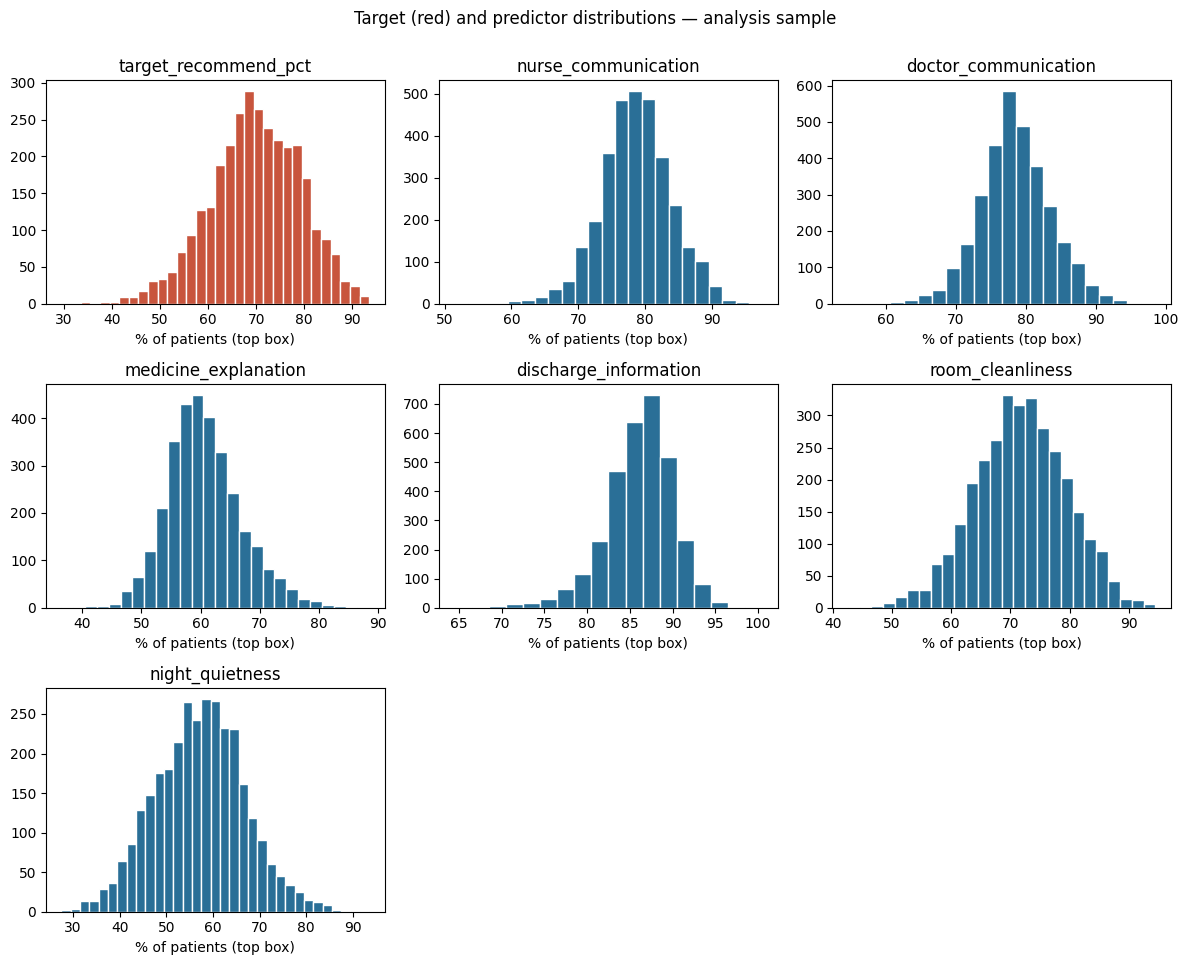

In [17]:
plot_cols = [TARGET_COL] + PREDICTOR_COLS
n_rows = int(np.ceil(len(plot_cols) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(12, 3.2 * n_rows))
for ax, col in zip(axes.flat, plot_cols):
    lo, hi = int(analysis_hospitals[col].min()), int(analysis_hospitals[col].max())
    ax.hist(analysis_hospitals[col], bins=np.arange(lo - 0.5, hi + 1.5, 2),
            color="#c8553d" if col == TARGET_COL else "#2a6f97", edgecolor="white")
    ax.set_title(col); ax.set_xlabel("% of patients (top box)")
for ax in list(axes.flat)[len(plot_cols):]:
    ax.axis("off")
fig.suptitle("Target (red) and predictor distributions — analysis sample", y=1.0)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 3 - Feature engineering
All features are built from the **cleaned** analysis sample only (cleaning is finished before this point).

| Feature | Formula | Why | Usage rule |
|---|---|---|---|
| F1 `census_region` | US Census region from `state`; PR and other territories → `Territory` | Regional control / descriptive comparison | `Territory` is tiny (≈10 hospitals): merge or drop it before one-hot encoding |
| F2 `log_completed_surveys` | `ln(completed_surveys)` | Survey counts are heavily right-skewed (skew ≈ 4.4); the log is usable as a control | Use instead of `completed_surveys` in linear models |
| F3 `meets_300_survey_target` | 1 if `completed_surveys ≥ 300` | CMS asks hospitals to aim for 300 surveys/year; marks hospitals with full-precision scores. **Not** a hospital-size measure (count depends on sampling and response rate) | Don't use together with F2 |
| F4 `gap_nurse_minus_doctor` | `nurse_communication − doctor_communication` | Is nurse-vs-doctor balance related to recommendation? | Exact linear combination: **never** include with *both* nurse and doctor communication (perfect collinearity) |
| F5 `target_high_recommend` | 1 if `target_recommend_pct ≥` cutoff (median or top quartile) | Binary target for classification | Never use `target_recommend_pct` as a predictor for it. For a train/test workflow, recompute the cutoff on the training set |
| Flags `flag_shorter_period` | 1 if CMS footnote 3 present | Results cover a shorter period; kept, but available for sensitivity checks | Descriptive / sensitivity only |

In [18]:
features = analysis_hospitals.copy()

# F1 census region (explicit mapping; nothing falls through silently)
CENSUS_REGION = {**dict.fromkeys("CT ME MA NH RI VT NJ NY PA".split(), "Northeast"),
                 **dict.fromkeys("IL IN MI OH WI IA KS MN MO NE ND SD".split(), "Midwest"),
                 **dict.fromkeys("DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX".split(), "South"),
                 **dict.fromkeys("AZ CO ID MT NV NM UT WY AK CA HI OR WA".split(), "West"),
                 **dict.fromkeys("PR GU VI AS MP".split(), "Territory")}
features["census_region"] = features["state"].map(CENSUS_REGION)
unmapped_states = features.loc[features["census_region"].isna(), "state"].unique()
assert len(unmapped_states) == 0, f"States without a region: {unmapped_states}"

# F2 log of survey count
features["log_completed_surveys"] = np.log(features["completed_surveys"])

# F3 survey-target indicator
features["meets_300_survey_target"] = (features["completed_surveys"] >= SURVEY_TARGET).astype(int)

# F4 nurse vs doctor communication gap
features["gap_nurse_minus_doctor"] = features["nurse_communication"] - features["doctor_communication"]

# F5 binary target
target_cutoff = (features[TARGET_COL].median() if TARGET_CUTOFF_RULE == "median"
                 else features[TARGET_COL].quantile(.75))
features["target_high_recommend"] = (features[TARGET_COL] >= target_cutoff).astype(int)

# Footnote flags
for code_number, flag_name in FLAG_FOOTNOTE_CODES.items():
    features[flag_name] = features["cms_footnotes"].map(lambda s: int(code_number in extract_codes(s)))

class_split = features["target_high_recommend"].value_counts(normalize=True).mul(100).round(1)
ties = (features[TARGET_COL] == target_cutoff).sum()
print(f"F5 cutoff ({TARGET_CUTOFF_RULE}) = {target_cutoff:.0f}% | class split: high {class_split.get(1, 0)}% / "
      f"lower {class_split.get(0, 0)}% | {ties} hospitals sit exactly on the cutoff (assigned to 'high')")
print("\nF1 census_region:\n" + features["census_region"].value_counts().to_string())
print(f"\nF3 meets_300_survey_target: {features['meets_300_survey_target'].mean():.0%} of hospitals")
print("Footnote flags:", {name: int(features[name].sum()) for name in FLAG_FOOTNOTE_CODES.values()})
cleaning_log.append(("Feature engineering", len(features), f"target cutoff {target_cutoff:.0f}%"))

F5 cutoff (median) = 70% | class split: high 52.0% / lower 48.0% | 123 hospitals sit exactly on the cutoff (assigned to 'high')

F1 census_region:
census_region
South        1176
Midwest       840
West          668
Northeast     478
Territory      10

F3 meets_300_survey_target: 76% of hospitals
Footnote flags: {'flag_shorter_period': 4}


## Part 4: Diagnostics: correlation and multicollinearity
**What:** correlation matrix and VIF of the six predictors. Nothing is changed here.
**Why:** HCAHPS dimensions move together (a "halo effect"). VIF > 5 means individual regression coefficients are unstable —
this motivates PCA and wording results as "most strongly associated with", not "causes".

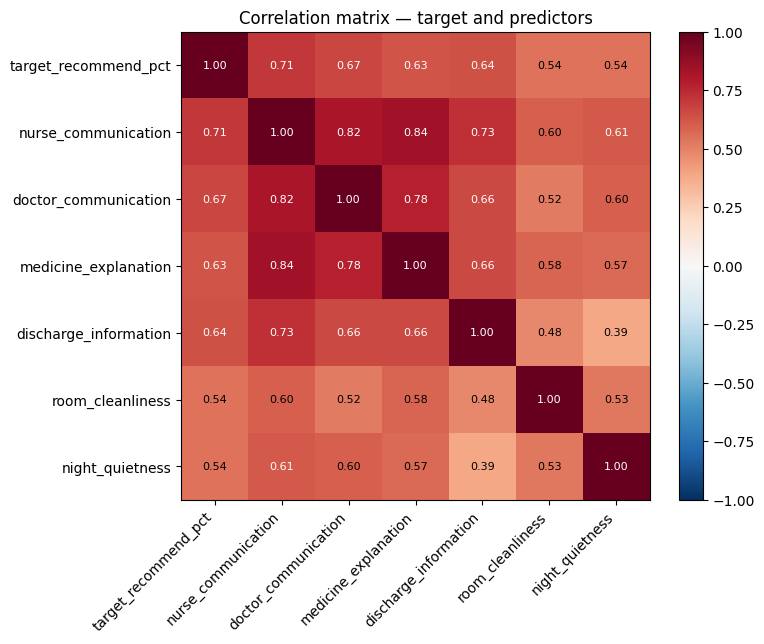

VIF:
nurse_communication      5.34
doctor_communication     3.60
medicine_explanation     3.83
discharge_information    2.26
room_cleanliness         1.73
night_quietness          1.83


In [19]:
correlation_matrix = features[[TARGET_COL] + PREDICTOR_COLS].corr().round(2)
correlation_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_matrix))); ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_matrix))); ax.set_yticklabels(correlation_matrix.columns)
for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix)):
        value = correlation_matrix.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.6 else "black")
fig.colorbar(im); ax.set_title("Correlation matrix — target and predictors")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
X_with_const = add_constant(features[PREDICTOR_COLS])
vif = pd.Series([variance_inflation_factor(X_with_const.values, i) for i in range(1, X_with_const.shape[1])],
                index=PREDICTOR_COLS, name="VIF").round(2)
print("VIF:\n" + vif.to_string())

## Part 5-Export
* `hcahps_model_ready.csv` — **the modeling file**, one row per hospital, raw % scale, columns ordered by role.
* `data_dictionary.csv` — every column: role, source measure, description, level of measurement, data type.
* `cleaning_log.csv` — hospitals remaining after each step.

**Reading the files back:** `pd.read_csv(path, dtype={"facility_id": str})` — otherwise `010001` becomes `10001`.

In [20]:
IDENTIFIER_COLS = ["facility_id", "facility_name", "city", "state"]
SURVEY_CONTEXT_COLS = ["completed_surveys", "response_rate_pct", "cms_footnotes"] + list(FLAG_FOOTNOTE_CODES.values())
ENGINEERED_COLS = ["census_region", "log_completed_surveys", "meets_300_survey_target", "gap_nurse_minus_doctor"]
FINAL_COLUMN_ORDER = (IDENTIFIER_COLS + SURVEY_CONTEXT_COLS + [TARGET_COL, "target_high_recommend"]
                      + PREDICTOR_COLS + ITEM_COLS + ENGINEERED_COLS + ALT_OUTCOME_COLS)

model_ready = features.reset_index()[FINAL_COLUMN_ORDER]
model_ready["completed_surveys"] = model_ready["completed_surveys"].astype("Int64")
model_ready["response_rate_pct"] = model_ready["response_rate_pct"].astype("Int64")
model_ready["alt_outcome_summary_star"] = model_ready["alt_outcome_summary_star"].astype("Int64")

# Final integrity checks
assert model_ready["facility_id"].is_unique
assert model_ready[[TARGET_COL] + PREDICTOR_COLS].notna().all().all()
assert model_ready[[TARGET_COL] + PREDICTOR_COLS + ITEM_COLS].apply(lambda c: c.between(0, 100)).all().all()

model_ready.to_csv(OUTPUT_DIR / "hcahps_model_ready.csv", index=False)

pd.DataFrame(cleaning_log, columns=["step", "hospitals_remaining", "note"]).to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)
print(f"Model-ready file: {model_ready.shape[0]:,} hospitals x {model_ready.shape[1]} columns")
model_ready.head()

Model-ready file: 3,172 hospitals x 33 columns


,facility_id,facility_name,city,state,completed_surveys,response_rate_pct,cms_footnotes,flag_shorter_period,target_recommend_pct,target_high_recommend,nurse_communication,doctor_communication,medicine_explanation,discharge_information,room_cleanliness,night_quietness,item_nurse_respect,item_nurse_listen,item_nurse_explain,item_doctor_respect,item_doctor_listen,item_doctor_explain,item_med_purpose,item_med_side_effects,item_discharge_help,item_discharge_symptoms,census_region,log_completed_surveys,meets_300_survey_target,gap_nurse_minus_doctor,alt_outcome_rating_9_10,alt_outcome_summary_star,alt_outcome_recommend_linear
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,DOTHAN,AL,1392,17,,0,79.0,1,76.0,80.0,59.0,87.0,70.0,65.0,85.0,72.0,72.0,87.0,78.0,75.0,74.0,45.0,83.0,90.0,South,7.238497,1,-4.0,72.0,4,91.0
1,010005,MARSHALL MEDICAL CENTERS,BOAZ,AL,745,17,,0,63.0,0,77.0,81.0,57.0,86.0,65.0,67.0,84.0,73.0,73.0,86.0,78.0,77.0,71.0,43.0,83.0,88.0,South,6.613384,1,-4.0,68.0,3,84.0
2,010006,NORTH ALABAMA MEDICAL CENTER,FLORENCE,AL,1781,18,,0,55.0,0,74.0,73.0,53.0,83.0,64.0,64.0,82.0,71.0,69.0,80.0,71.0,68.0,67.0,40.0,80.0,86.0,South,7.484930,1,1.0,61.0,2,80.0
3,010011,ST. VINCENT'S EAST,BIRMINGHAM,AL,1203,21,,0,69.0,0,78.0,79.0,57.0,85.0,63.0,61.0,85.0,74.0,74.0,86.0,76.0,75.0,72.0,43.0,84.0,85.0,South,7.092574,1,-1.0,70.0,3,86.0
4,010012,DEKALB REGIONAL MEDICAL CENTER,FORT PAYNE,AL,239,14,,0,59.0,0,80.0,80.0,60.0,87.0,58.0,60.0,86.0,78.0,75.0,86.0,79.0,75.0,75.0,45.0,86.0,89.0,South,5.476464,0,0.0,62.0,3,84.0


In [21]:
# Data dictionary: every column must have a description, or the export stops.
measure_descriptions = measure_inventory.set_index("measure_id")["answer_description"]
COLUMN_INFO = {   # column: (role, description, level of measurement)
    "facility_id":   ("Identifier", "CMS Certification Number (6 characters, keep as text)", "Nominal"),
    "facility_name": ("Identifier", "Hospital name", "Nominal"),
    "city":          ("Identifier", "City/town", "Nominal"),
    "state":         ("Identifier", "Two-letter state/territory code", "Nominal"),
    "completed_surveys": ("Survey context", "Number of completed HCAHPS surveys in the reporting period", "Ratio"),
    "response_rate_pct": ("Survey context", "Survey response rate (%)", "Ratio"),
    "cms_footnotes": ("Survey context", "All CMS footnote codes the hospital received, comma-separated (blank = none)", "Nominal"),
    "flag_shorter_period": ("Survey context", "1 = CMS footnote 3: results cover a shorter period than required", "Binary"),
    "target_recommend_pct": ("Target (regression)", "% of patients who would definitely recommend the hospital", "Ratio"),
    "target_high_recommend": ("Target (classification)", f"1 = target_recommend_pct >= {target_cutoff:.0f} ({TARGET_CUTOFF_RULE} cutoff)", "Binary"),
    "census_region": ("Engineered", "US Census region from state (PR etc. = Territory)", "Nominal"),
    "log_completed_surveys": ("Engineered", "Natural log of completed_surveys (reduces right skew)", "Interval"),
    "meets_300_survey_target": ("Engineered", f"1 = completed_surveys >= {SURVEY_TARGET} (CMS survey target); not a size measure", "Binary"),
    "gap_nurse_minus_doctor": ("Engineered", "nurse_communication - doctor_communication; never use with both of them", "Interval"),
}
for col, mid in {**PREDICTOR_MEASURES, **ITEM_MEASURES, **ALT_OUTCOME_MEASURES, **TARGET_MEASURE}.items():
    role = ("Predictor (composite)" if col in PREDICTOR_COLS else
            "Item-level predictor (substitute for its composite, never alongside it)" if col in ITEM_COLS else
            "Alternative outcome - NOT a predictor (same outcome, leakage)" if col in ALT_OUTCOME_COLS else
            COLUMN_INFO[col][0])
    level = "Ordinal (1-5)" if col == "alt_outcome_summary_star" else "Ratio"
    COLUMN_INFO[col] = (role, f"{measure_descriptions.get(mid, '')} (% of patients, top box)"
                        if col not in ("alt_outcome_summary_star", "alt_outcome_recommend_linear")
                        else measure_descriptions.get(mid, ""), level)

SOURCE_MEASURE = {**PREDICTOR_MEASURES, **ITEM_MEASURES, **ALT_OUTCOME_MEASURES, **TARGET_MEASURE}
undocumented = [c for c in model_ready.columns if c not in COLUMN_INFO]
assert not undocumented, f"Columns missing from the data dictionary: {undocumented}"

data_dictionary = pd.DataFrame([
    {"variable": col, "role": COLUMN_INFO[col][0], "source_measure_id": SOURCE_MEASURE.get(col, "derived" if COLUMN_INFO[col][0] == "Engineered" else ""),
     "description": COLUMN_INFO[col][1], "level_of_measurement": COLUMN_INFO[col][2], "dtype": str(model_ready[col].dtype)}
    for col in model_ready.columns])
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)
print("Saved:", *sorted(p.name for p in OUTPUT_DIR.iterdir()), sep="\n  ")
data_dictionary

Saved:
  cleaning_log.csv
  correlation_heatmap.png
  correlation_matrix.csv
  data_dictionary.csv
  descriptive_stats.csv
  distributions.png
  hcahps_model_ready.csv
  hcahps_wide_all_measures.csv
  measure_inventory.csv
  missingness_report.csv
  outlier_flags.csv


,variable,role,source_measure_id,description,level_of_measurement,dtype
0,facility_id,Identifier,,"CMS Certification Number (6 characters, keep as text)",Nominal,object
1,facility_name,Identifier,,Hospital name,Nominal,object
2,city,Identifier,,City/town,Nominal,object
3,state,Identifier,,Two-letter state/territory code,Nominal,object
4,completed_surveys,Survey context,,Number of completed HCAHPS surveys in the reporting period,Ratio,Int64
5,response_rate_pct,Survey context,,Survey response rate (%),Ratio,Int64
6,cms_footnotes,Survey context,,"All CMS footnote codes the hospital received, comma-separated (bla...",Nominal,object
7,flag_shorter_period,Survey context,,1 = CMS footnote 3: results cover a shorter period than required,Binary,int64
8,target_recommend_pct,Target (regression),H_RECMND_DY,"""YES"", patients would definitely recommend the hospital (% of pati...",Ratio,float64
9,target_high_recommend,Target (classification),,1 = target_recommend_pct >= 70 (median cutoff),Binary,int32


### Column-name mapping from v1 (for updating existing modeling code)
| v1 name | v2 name |
|---|---|
| `recommend_pct` / `high_recommend` | `target_recommend_pct` / `target_high_recommend` |
| `nurse_comm`, `doctor_comm`, `medicine_comm`, `discharge_info`, `cleanliness`, `quietness` | `nurse_communication`, `doctor_communication`, `medicine_explanation`, `discharge_information`, `room_cleanliness`, `night_quietness` |
| `nurse_respect` … `disch_symptom_info` | `item_nurse_respect` … `item_discharge_symptoms` |
| `overall_rating_9_10`, `summary_star_rating`, `recommend_linear` | `alt_outcome_rating_9_10`, `alt_outcome_summary_star`, `alt_outcome_recommend_linear` |
| `n_surveys`, `response_rate`, `n_surveys_footnote` | `completed_surveys`, `response_rate_pct`, `cms_footnotes` (all codes, all columns) |
| `region`, `large_sample`, `nurse_minus_doctor` | `census_region`, `meets_300_survey_target`, `gap_nurse_minus_doctor` |
| — | new: `log_completed_surveys`, `flag_shorter_period` |